# Stellar-mass HOD with `halogal`

This notebook introduces the stellar-mass-selected halo occupation distribution in `halogal`: `MstarHODModel` together with `MstarObservables`. It mirrors the UV tutorial (`basic_usage.ipynb`), but selects galaxies by stellar mass instead of UV magnitude.

**What you'll learn:**
1. The stellar-halo mass relation (`SHMRModel`)
2. Creating an `MstarHODModel` and its occupation functions
3. Computing the stellar mass function (SMF) with `MstarObservables`
4. Galaxy bias, mean halo mass and number densities for stellar-mass samples
5. Changing parameters inline, the pattern used for MCMC
6. Angular clustering of stellar-mass samples with `halomod` (optional)

### Theoretical framework

**Stellar-halo mass relation (SHMR).** Stellar mass is a fraction of the halo's baryons,

$$M_\star(M_h) = f_b\,\varepsilon(M_h)\,M_h, \qquad
\varepsilon(M_h) = \frac{2\,\varepsilon_0}{(M_h/M_c)^{-a} + (M_h/M_c)^{b}},$$

with $f_b$ the cosmic baryon fraction. This is the same double power-law efficiency as the UVHMR. The UV model applies it to the halo *accretion rate* to get an SFR, whereas the SHMR applies it to the halo *mass*.

**Central occupation.** Centrals have log-normal scatter $\sigma_{M_\star}$ (in dex) in stellar mass at fixed halo mass. The mean number of centrals above a threshold $\log M_\star^{\rm th}$ is

$$\langle N_{\rm cen}\rangle = \frac12\left[1 + {\rm erf}\left(\frac{\log M_\star(M_h) - \log M_\star^{\rm th}}{\sqrt2\,\sigma_{M_\star}}\right)\right].$$

**Satellite occupation.** This is the same three-parameter model as for UV samples. Satellites follow a power law above a cutoff mass $M_{\rm cut}$, normalised by $M_{\rm sat}$ with slope $\alpha_{\rm sat}$:

$$\langle N_{\rm sat}(M_h\,|\,M_\star^{\rm th})\rangle = \left(\frac{M_h - M_{\rm cut}}{M_{\rm sat}}\right)^{\alpha_{\rm sat}}, \qquad M_h > M_{\rm cut}.$$

The total occupation is

$$\langle N_{\rm tot}(M_h)\rangle = \langle N_{\rm cen}(M_h)\rangle\left[\,1 + \langle N_{\rm sat}(M_h)\rangle\,\right].$$

In code, `model.Nsat()` returns the satellite term already multiplied by the central occupation, $\langle N_{\rm cen}\rangle\langle N_{\rm sat}\rangle$. So `model.Ngal() = model.Ncen() + model.Nsat()` is $\langle N_{\rm tot}\rangle$.

> **Caveat.** The default $\varepsilon_0, M_c, a, b, M_{\rm cut}, M_{\rm sat}, \alpha_{\rm sat}$ are the UV fits of Shuntov et al. (2025). They have **not** been calibrated against stellar mass functions. The default $\sigma_{M_\star} = 0.3$ dex is a placeholder. Treat the numbers below as illustrations of the API, not as predictions.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from halogal import SHMRModel, MstarHODModel, Observables, MstarObservables
from halogal.config import BARYON_FRACTION, DEFAULT_HOD_PARAMS

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

print(f"Baryon fraction f_b = {BARYON_FRACTION:.3f}")
print(f"Default sigma_Mstar = {DEFAULT_HOD_PARAMS['sigma_Mstar']} dex")

Baryon fraction f_b = 0.160
Default sigma_Mstar = 0.3 dex


## Part 1: Creating a stellar-mass HOD model

`MstarHODModel` combines two pieces:
- **`SHMRModel`**: the stellar-halo mass relation, $M_\star(M_h)$
- **`BaseHODModel`**: the central and satellite occupation functions, shared with `UVHODModel`

Only the redshift is required; every other parameter falls back to the defaults in `halogal.config`. The scatter parameter is called `sigma_Mstar` (in dex), where the UV model uses `sigma_UV` (in mag).

In [2]:
model = MstarHODModel(
    z=6.0,              # Redshift
    eps0=0.19,          # Star formation efficiency normalisation
    Mc=10**11.64,       # Characteristic halo mass [M_sun]
    a=0.69,             # Low-mass slope
    b=0.65,             # High-mass slope
    sigma_Mstar=0.3,    # Scatter in log10(Mstar) at fixed Mh [dex]
    Mcut=10**9.57,      # Satellite cutoff mass [M_sun]
    Msat=10**12.65,     # Satellite normalisation mass [M_sun]
    asat=0.85,          # Satellite power-law slope
)

print(model)
print()
print("Parameters accepted by update_parameters / inline overrides:")
print(model.param_names())

MstarHODModel at z=6.0
HMR Parameters:
  eps0 = 0.190
  Mc = 4.37e+11 M_sun
  a = 0.69
  b = 0.65

HOD Parameters:
  sigma_Mstar = 0.30 dex
  Mcut = 3.72e+09 M_sun
  Msat = 4.47e+12 M_sun
  asat = 0.85

Parameters accepted by update_parameters / inline overrides:
('z', 'eps0', 'Mc', 'a', 'b', 'sigma_Mstar', 'Mcut', 'Msat', 'asat')


## Part 2: The stellar-halo mass relation

`model.Mstar(Mh)` gives the mean stellar mass of a halo, and `model.Mhalo(Mstar)` inverts it numerically. `MstarHODModel` inherits all of these methods from `SHMRModel`, so a bare `SHMRModel(z=...)` works the same way if you don't need occupations.

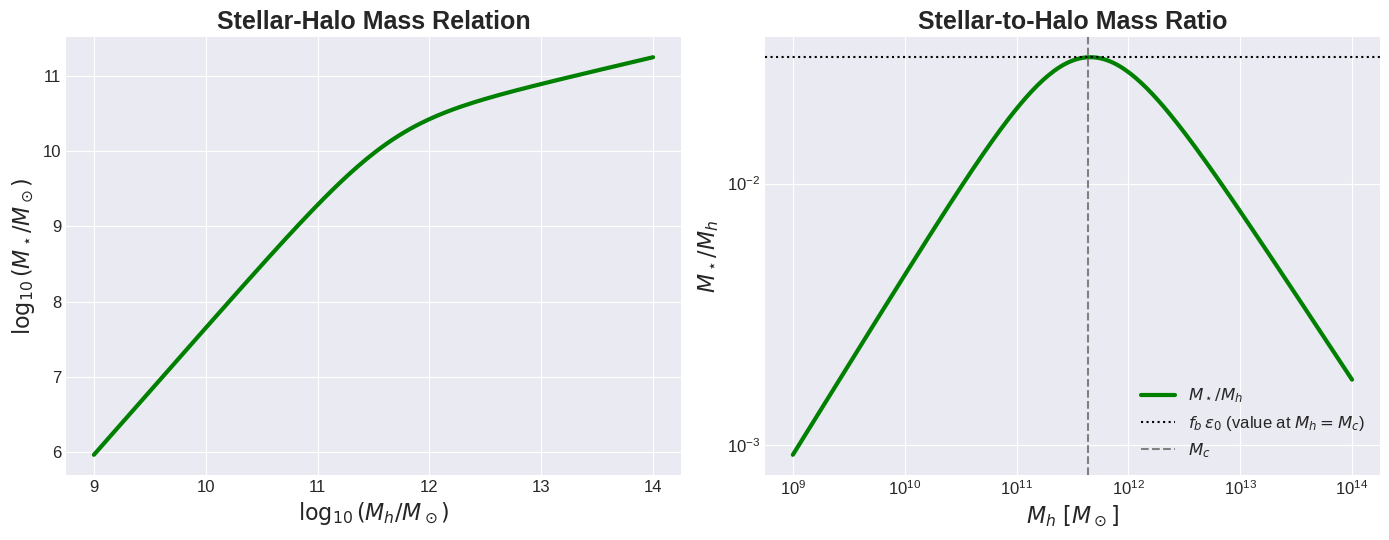

In [3]:
Mh = np.logspace(9, 14, 200)
Mstar = model.Mstar(Mh)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(np.log10(Mh), np.log10(Mstar), 'g-', linewidth=3)
axes[0].set_xlabel(r'$\log_{10}(M_h / M_\odot)$', fontsize=16)
axes[0].set_ylabel(r'$\log_{10}(M_\star / M_\odot)$', fontsize=16)
axes[0].set_title('Stellar-Halo Mass Relation', fontsize=18, fontweight='bold')

axes[1].loglog(Mh, Mstar / Mh, 'g-', linewidth=3, label=r'$M_\star / M_h$')
axes[1].axhline(BARYON_FRACTION * model.eps0, color='k', ls=':',
                label=r'$f_b\,\varepsilon_0$ (value at $M_h = M_c$)')
axes[1].axvline(model.Mc, color='gray', ls='--', label=r'$M_c$')
axes[1].set_xlabel(r'$M_h\ [M_\odot]$', fontsize=16)
axes[1].set_ylabel(r'$M_\star / M_h$', fontsize=16)
axes[1].set_title('Stellar-to-Halo Mass Ratio', fontsize=18, fontweight='bold')
axes[1].legend(fontsize=12)

for ax in axes:
    ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

In [4]:
# Invert the relation: which halo hosts a galaxy of a given stellar mass?
log_Mstar = np.array([8.0, 9.0, 10.0, 11.0])
Mh_host = model.Mhalo(10**log_Mstar)       # Mhalo takes linear Mstar

for lm, mh in zip(log_Mstar, Mh_host):
    print(f"log10 Mstar = {lm:4.1f}  ->  log10 Mh = {np.log10(mh):.2f}")

# Round trip
print("\nRound trip Mstar(Mhalo(Mstar)):", np.log10(model.Mstar(Mh_host)))

log10 Mstar =  8.0  ->  log10 Mh = 10.21
log10 Mstar =  9.0  ->  log10 Mh = 10.82
log10 Mstar = 10.0  ->  log10 Mh = 11.53
log10 Mstar = 11.0  ->  log10 Mh = 13.29

Round trip Mstar(Mhalo(Mstar)): [ 7.99996826  8.99998401 10.00000172 11.00000651]


## Part 3: Halo occupation distribution

`Ncen`, `Nsat` and `Ngal` take a halo mass and a **threshold in $\log_{10}(M_\star/M_\odot)$**. A galaxy counts if it is *more massive* than the threshold. For the UV model, a galaxy counts if it is *brighter* than a magnitude threshold.

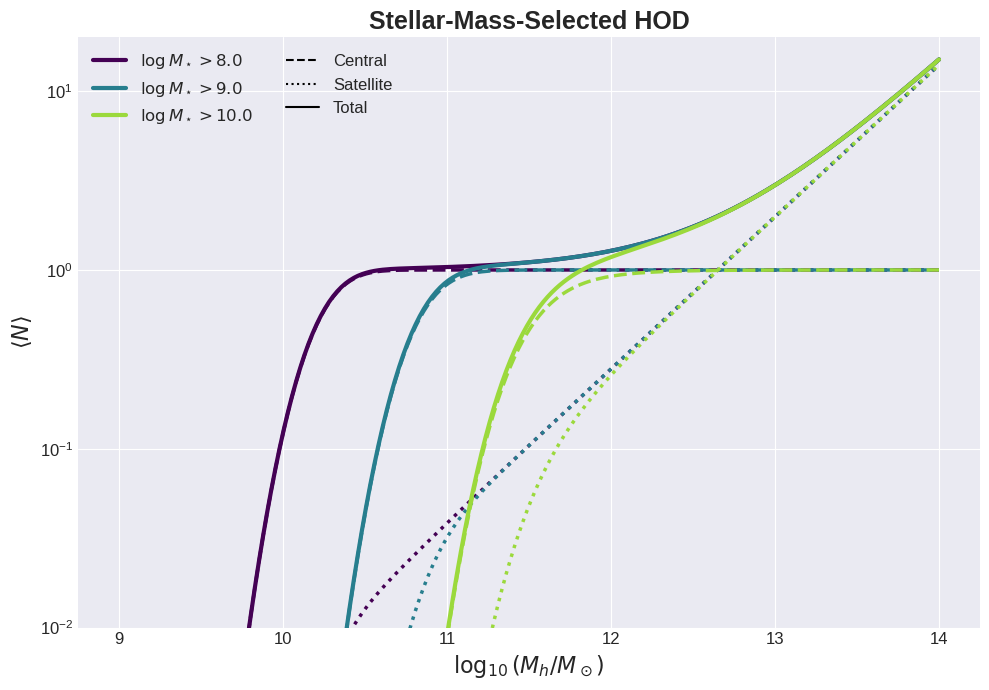

In [5]:
Mh_range = np.logspace(9, 14, 200)
thresholds = [8.0, 9.0, 10.0]
colors = plt.cm.viridis(np.linspace(0, 0.85, len(thresholds)))

fig, ax = plt.subplots(figsize=(10, 7))
for thresh, c in zip(thresholds, colors):
    label = rf'$\log M_\star > {thresh}$'
    ax.plot(np.log10(Mh_range), model.Ncen(Mh_range, thresh), '--', color=c, lw=2.5)
    ax.plot(np.log10(Mh_range), model.Nsat(Mh_range, thresh), ':', color=c, lw=2.5)
    ax.plot(np.log10(Mh_range), model.Ngal(Mh_range, thresh), '-', color=c, lw=3, label=label)

ax.plot([], [], 'k--', label='Central')
ax.plot([], [], 'k:', label='Satellite')
ax.plot([], [], 'k-', label='Total')
ax.set_yscale('log')
ax.set_ylim(1e-2, 20)
ax.set_xlabel(r'$\log_{10}(M_h / M_\odot)$', fontsize=16)
ax.set_ylabel(r'$\langle N \rangle$', fontsize=16)
ax.set_title('Stellar-Mass-Selected HOD', fontsize=18, fontweight='bold')
ax.legend(fontsize=12, ncol=2)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

### Effect of the scatter `sigma_Mstar`

$\langle N_{\rm cen}\rangle = 0.5$ exactly where the *mean* stellar mass equals the threshold, $M_h = M_h(M_\star^{\rm th})$. Larger scatter widens the transition around that point, letting more low-mass haloes host a galaxy above the threshold.

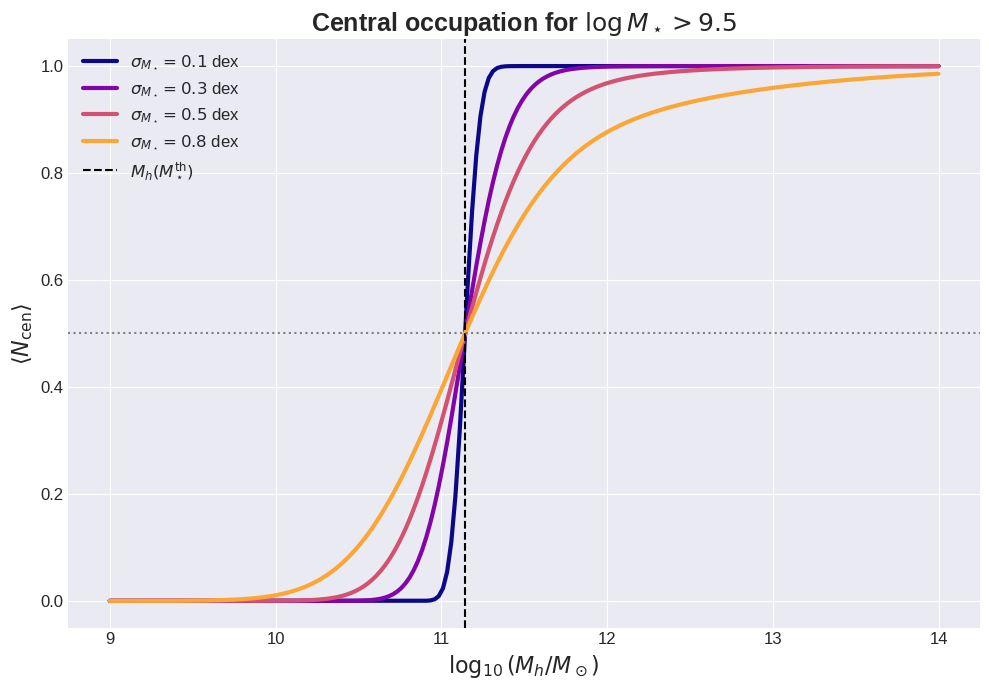

In [6]:
thresh = 9.5
Mh_half = model.Mhalo(10**thresh)

fig, ax = plt.subplots(figsize=(10, 7))
for s, c in zip([0.1, 0.3, 0.5, 0.8], plt.cm.plasma(np.linspace(0, 0.8, 4))):
    m = MstarHODModel(z=6.0, sigma_Mstar=s)
    ax.plot(np.log10(Mh_range), m.Ncen(Mh_range, thresh), color=c, lw=3,
            label=rf'$\sigma_{{M_\star}} = {s}$ dex')

ax.axvline(np.log10(Mh_half), color='k', ls='--', label=r'$M_h(M_\star^{\rm th})$')
ax.axhline(0.5, color='gray', ls=':')
ax.set_xlabel(r'$\log_{10}(M_h / M_\odot)$', fontsize=16)
ax.set_ylabel(r'$\langle N_{\rm cen} \rangle$', fontsize=16)
ax.set_title(rf'Central occupation for $\log M_\star > {thresh}$', fontsize=18, fontweight='bold')
ax.legend(fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

## Part 4: The stellar mass function

`Observables(model)` returns the right subclass for the model you pass it: a `MstarObservables` here, or a `UVObservables` for a `UVHODModel`. You can also build `MstarObservables(model)` directly.

`stellar_mass_function(log10_Mstar, dlog10_Mstar=0.05)` gives $\Phi(\log M_\star)$ in Mpc$^{-3}$ dex$^{-1}$. It integrates the occupation in each stellar-mass bin over the halo mass function.

In [7]:
obs = Observables(model)
print(type(obs).__name__)

logM = np.linspace(7.0, 11.5, 46)
phi = obs.stellar_mass_function(logM)

print(f"  log Mstar range: {logM.min():.1f} to {logM.max():.1f}")
print(f"  Phi range: {phi.min():.2e} to {phi.max():.2e} Mpc^-3 dex^-1")

MstarObservables
  log Mstar range: 7.0 to 11.5
  Phi range: 5.60e-08 to 2.01e-01 Mpc^-3 dex^-1


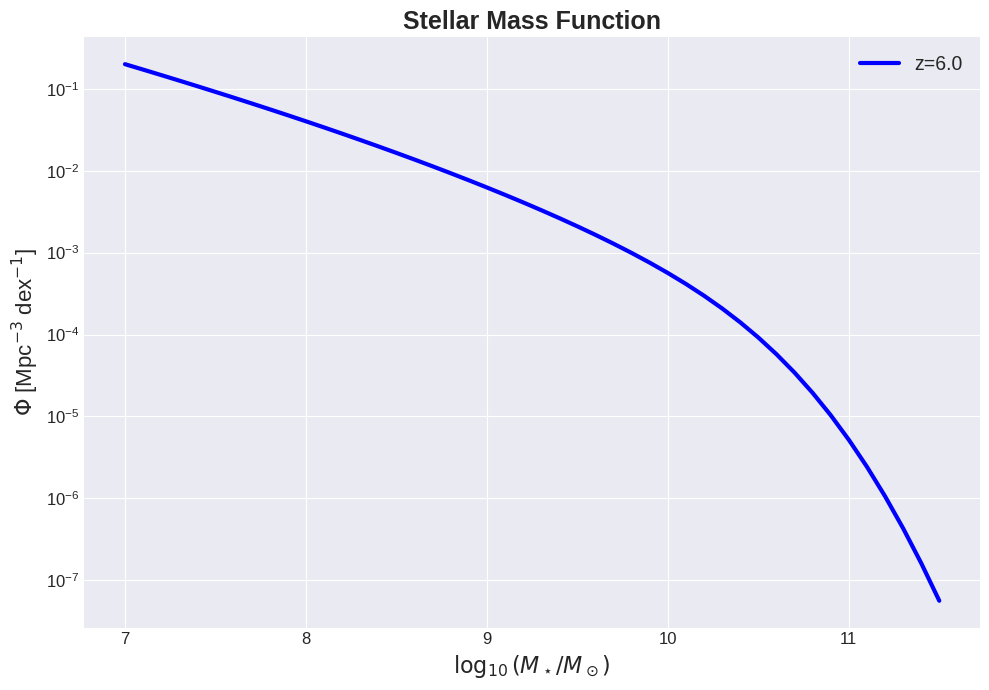

In [8]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.semilogy(logM, phi, 'b-', linewidth=3, label=f'z={model.z}')
ax.set_xlabel(r'$\log_{10}(M_\star / M_\odot)$', fontsize=16)
ax.set_ylabel(r'$\Phi$ [Mpc$^{-3}$ dex$^{-1}$]', fontsize=16)
ax.set_title('Stellar Mass Function', fontsize=18, fontweight='bold')
ax.legend(fontsize=14)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

In [9]:
# Consistency check: the cumulative number density above a threshold
# equals the integral of the SMF above it.
thresh = 9.0
logM_fine = np.linspace(thresh, 12.5, 141)
n_from_smf = np.trapz(obs.stellar_mass_function(logM_fine), logM_fine)
n_direct = obs.number_density(thresh)

print(f"n(log Mstar > {thresh}) from integrating the SMF: {n_from_smf:.3e} Mpc^-3")
print(f"n(log Mstar > {thresh}) from number_density():    {n_direct:.3e} Mpc^-3")

n(log Mstar > 9.0) from integrating the SMF: 2.680e-03 Mpc^-3
n(log Mstar > 9.0) from number_density():    2.678e-03 Mpc^-3


## Part 5: Galaxy bias and mean properties

These methods are shared with the UV observables; only the units of the selection variable change.
- `galaxy_bias(log10_Mstar)`: bias in stellar-mass bins
- `mean_halo_mass(thresh)`, `mean_bias(thresh)`, `number_density(thresh)`: properties of threshold samples, $\log M_\star > $ `thresh`

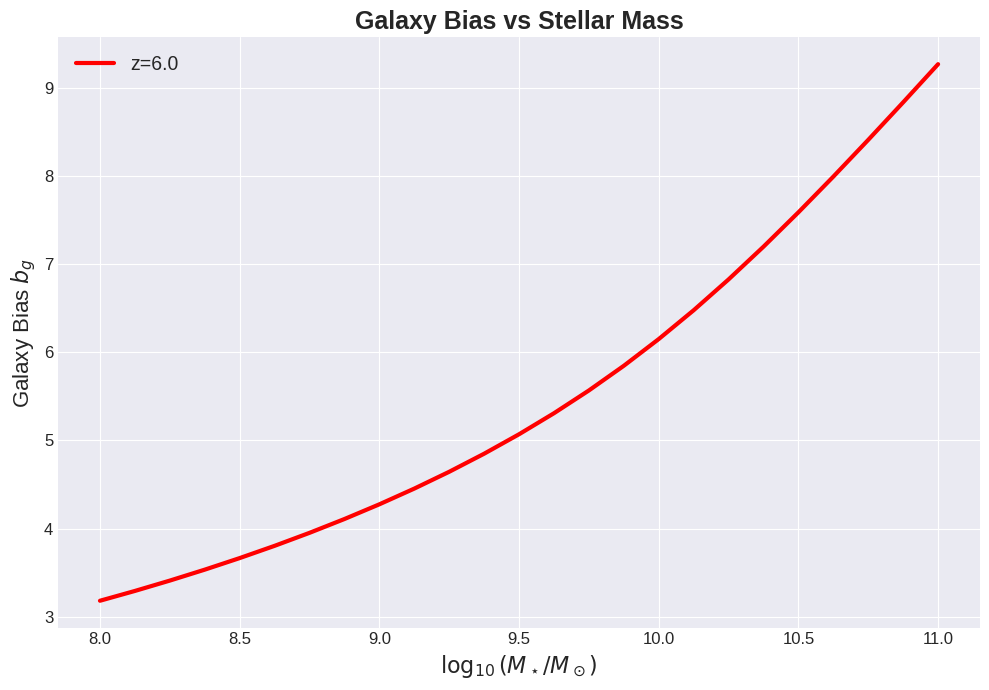

In [10]:
logM_b = np.linspace(8.0, 11.0, 25)
bias = obs.galaxy_bias(logM_b)

fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(logM_b, bias, 'r-', linewidth=3, label=f'z={model.z}')
ax.set_xlabel(r'$\log_{10}(M_\star / M_\odot)$', fontsize=16)
ax.set_ylabel('Galaxy Bias $b_g$', fontsize=16)
ax.set_title('Galaxy Bias vs Stellar Mass', fontsize=18, fontweight='bold')
ax.legend(fontsize=14)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

In [11]:
print(f"{'threshold':>10} {'n [Mpc^-3]':>12} {'<log Mh>':>9} {'<b>':>6}")
print("-" * 41)
for thresh in [8.0, 8.5, 9.0, 9.5, 10.0, 10.5]:
    n = obs.number_density(thresh)
    log_mh = obs.mean_halo_mass(thresh)
    b = obs.mean_bias(thresh)
    print(f"{'> ' + str(thresh):>10} {n:12.3e} {log_mh:9.2f} {b:6.2f}")

 threshold   n [Mpc^-3]  <log Mh>    <b>
-----------------------------------------
     > 8.0    2.140e-02     10.55   3.70
     > 8.5    8.004e-03     10.79   4.24
     > 9.0    2.678e-03     11.04   4.91
     > 9.5    7.530e-04     11.29   5.74
    > 10.0    1.551e-04     11.56   6.81
    > 10.5    1.730e-05     11.82   8.14


## Part 6: Parameter exploration

Every observable method accepts **inline parameter overrides**. The names are those in `model.param_names()`, and each override is applied to the underlying model before computing. It **persists** afterwards. This is the pattern to use inside an MCMC loop.

Parameter names are model-specific. Passing a UV-only name such as `sigma_UV` to a stellar-mass observable raises a `TypeError` rather than being silently ignored.

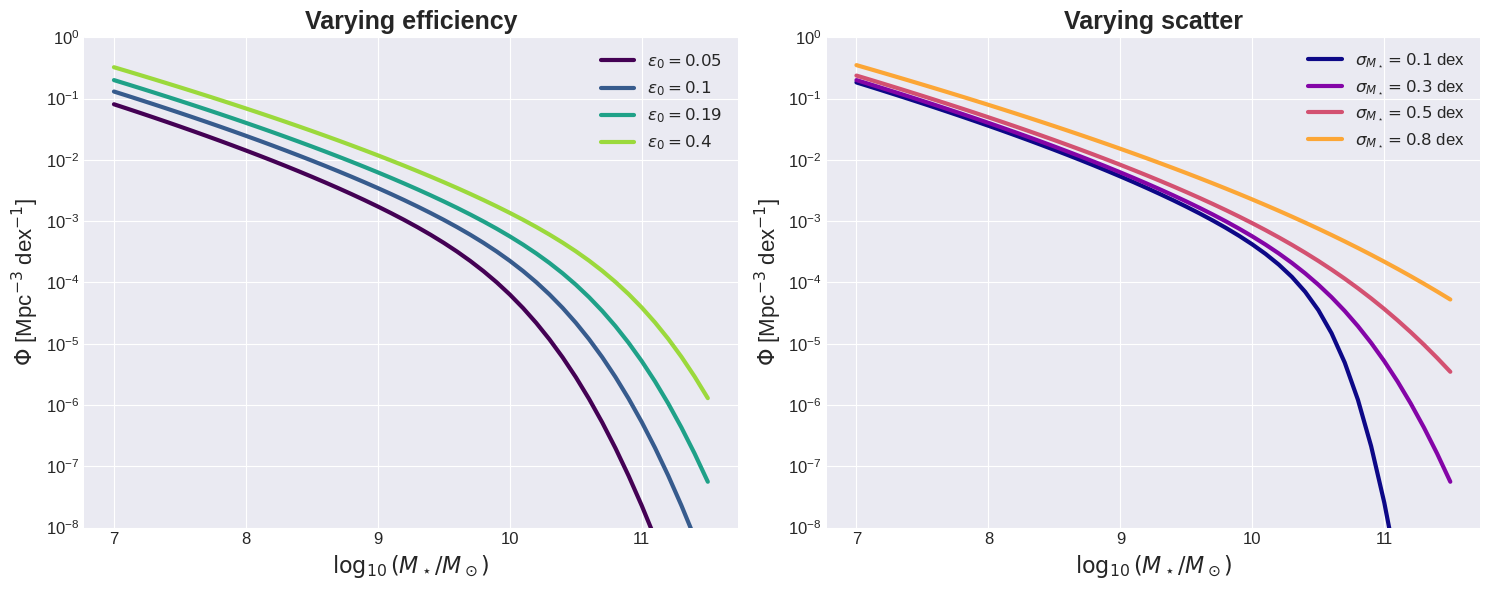

TypeError: unrecognised parameter(s) ['sigma_UV']; expected any of ['Mc', 'Mcut', 'Msat', 'a', 'asat', 'b', 'eps0', 'sigma_Mstar', 'z']


In [12]:
obs_var = Observables(MstarHODModel(z=6.0))
logM = np.linspace(7.0, 11.5, 46)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for eps0, c in zip([0.05, 0.1, 0.19, 0.4], plt.cm.viridis(np.linspace(0, 0.85, 4))):
    axes[0].semilogy(logM, obs_var.stellar_mass_function(logM, eps0=eps0),
                     color=c, lw=3, label=rf'$\varepsilon_0 = {eps0}$')
obs_var.hod_model.update_parameters(eps0=0.19)      # restore

for s, c in zip([0.1, 0.3, 0.5, 0.8], plt.cm.plasma(np.linspace(0, 0.8, 4))):
    axes[1].semilogy(logM, obs_var.stellar_mass_function(logM, sigma_Mstar=s),
                     color=c, lw=3, label=rf'$\sigma_{{M_\star}} = {s}$ dex')
obs_var.hod_model.update_parameters(sigma_Mstar=0.3)  # restore

for ax, title in zip(axes, ['Varying efficiency', 'Varying scatter']):
    ax.set_xlabel(r'$\log_{10}(M_\star / M_\odot)$', fontsize=16)
    ax.set_ylabel(r'$\Phi$ [Mpc$^{-3}$ dex$^{-1}$]', fontsize=16)
    ax.set_title(title, fontsize=18, fontweight='bold')
    ax.set_ylim(1e-8, 1)
    ax.legend(fontsize=12)
    ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

# Wrong parameter names are caught
try:
    obs_var.stellar_mass_function(logM, sigma_UV=0.5)
except TypeError as err:
    print("TypeError:", err)

### Redshift evolution

The SHMR has no explicit redshift dependence. With fixed parameters, the SMF evolves only through the halo mass function. `z` is itself an inline parameter, and the HMF is cached per redshift. In a real application you would also evolve the HOD parameters with $z$.

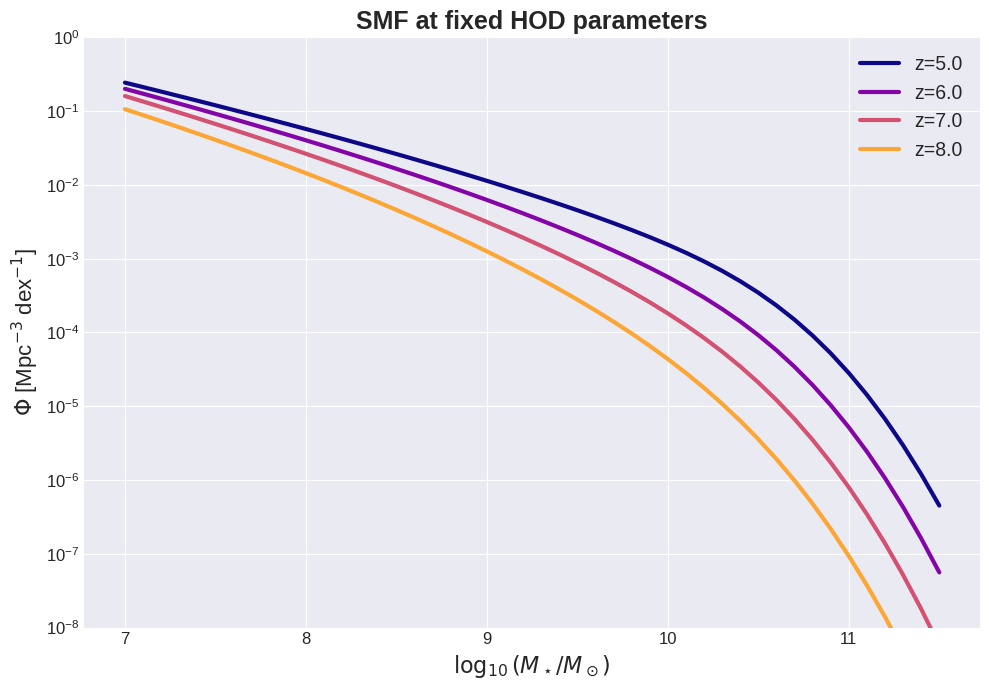

In [13]:
obs_z = Observables(MstarHODModel(z=6.0))
redshifts = [5.0, 6.0, 7.0, 8.0]

fig, ax = plt.subplots(figsize=(10, 7))
for z, c in zip(redshifts, plt.cm.plasma(np.linspace(0, 0.8, len(redshifts)))):
    ax.semilogy(logM, obs_z.stellar_mass_function(logM, z=z), color=c, lw=3, label=f'z={z}')

ax.set_xlabel(r'$\log_{10}(M_\star / M_\odot)$', fontsize=16)
ax.set_ylabel(r'$\Phi$ [Mpc$^{-3}$ dex$^{-1}$]', fontsize=16)
ax.set_title('SMF at fixed HOD parameters', fontsize=18, fontweight='bold')
ax.set_ylim(1e-8, 1)
ax.legend(fontsize=14)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

## Part 7: Angular clustering (optional, requires `halomod`)

The correlation-function interface works the same way as for UV samples:
1. `initialize_correlation_model(thresh1, thresh2=None, ...)` builds the halomod model once. This is slow.
2. `update_correlation_model(...)` then recomputes quickly when parameters or thresholds change.

For stellar-mass samples, the thresholds are:
- `thresh1`: the **lower** stellar-mass limit, $\log M_\star > $ `thresh1`.
- `thresh2`: an optional **upper** limit for a stellar-mass bin. It must be larger than `thresh1`. `None` gives a threshold sample.

Two notes:
- **Mass grid.** A scatter of 0.3 dex in $M_\star$ corresponds to a narrow window in halo mass, roughly $\sigma_{M_\star}/(1+a)$. halomod's default `dlog10m = 0.1` undersamples it, so a finer grid is passed below.
- **HMF switch.** Once a correlation model exists, `obs.stellar_mass_function()` and the other observables use halomod's HMF instead of Colossus's, for consistency with the clustering.

In [14]:
obs_cf = Observables(MstarHODModel(z=6.0))

# Threshold sample: log10 Mstar > 9.0 (slow: builds the halomod model)
result = obs_cf.initialize_correlation_model(
    9.0, correlation_type='angular', dlog10m=0.02)

theta_ref, w_ref = result['separation'], result['correlation']
print(f"theta: {theta_ref.min():.1f} - {theta_ref.max():.0f} arcsec, {len(theta_ref)} points")

/nvme/scratch/software/anaconda3/envs/more_and_more_galfind/lib/python3.12/site-packages/halomod/integrate_corr.py:567: UserWarning: Filter function p(x) did not integrate to 1 (0.9544997333075783). Tentatively re-normalising.
  p1 = _check_p(p1, z if p_of_z else x)
/nvme/scratch/software/anaconda3/envs/more_and_more_galfind/lib/python3.12/site-packages/hmf/_internals/_cache.py:115: UserWarning: Using halofit for tracer stats is only valid up to quasi-linear scales k<~1 (h/Mpc).
  value = f(self)


theta: 1.0 - 7200 arcsec, 100 points


/nvme/scratch/software/anaconda3/envs/more_and_more_galfind/lib/python3.12/site-packages/halomod/integrate_corr.py:567: UserWarning: Filter function p(x) did not integrate to 1 (0.9544997333075783). Tentatively re-normalising.
  p1 = _check_p(p1, z if p_of_z else x)


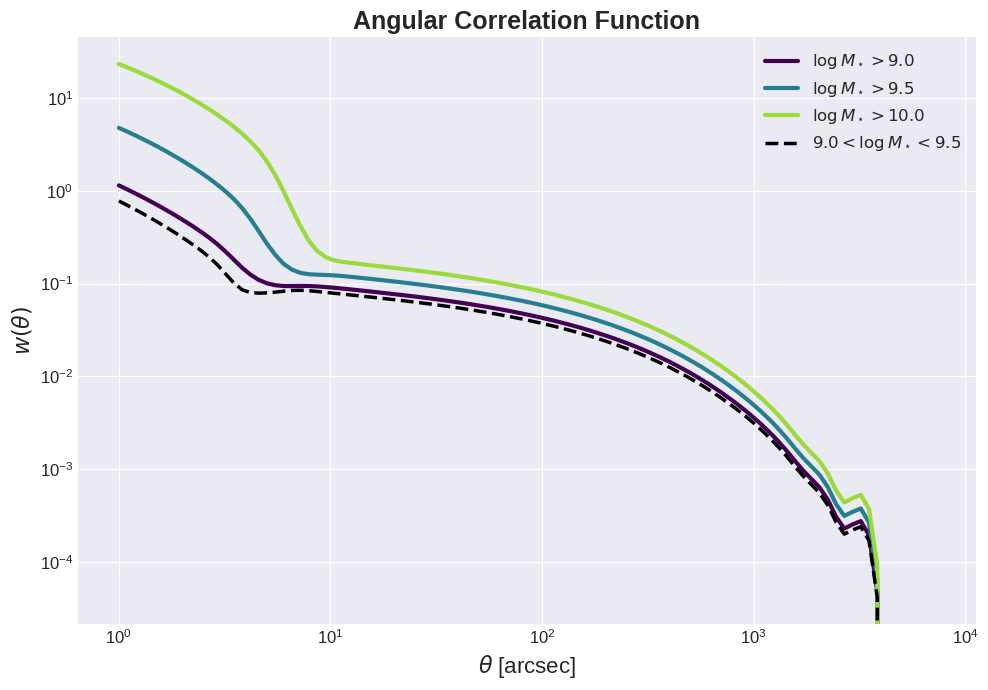

In [15]:
# Fast updates: change the threshold without rebuilding the model
fig, ax = plt.subplots(figsize=(10, 7))

for thresh, c in zip([9.0, 9.5, 10.0], plt.cm.viridis(np.linspace(0, 0.85, 3))):
    res = obs_cf.update_correlation_model(thresh1=thresh)
    ax.loglog(res['separation'], res['correlation'], color=c, lw=3,
              label=rf'$\log M_\star > {thresh}$')

# A stellar-mass bin, 9.0 < log10 Mstar < 9.5
res = obs_cf.update_correlation_model(thresh1=9.0, thresh2=9.5)
ax.loglog(res['separation'], res['correlation'], 'k--', lw=2.5,
          label=r'$9.0 < \log M_\star < 9.5$')

ax.set_xlabel(r'$\theta$ [arcsec]', fontsize=16)
ax.set_ylabel(r'$w(\theta)$', fontsize=16)
ax.set_title('Angular Correlation Function', fontsize=18, fontweight='bold')
ax.legend(fontsize=12)
ax.tick_params(labelsize=12)
plt.tight_layout()
plt.show()

In [16]:
# MCMC-style loop: update HOD parameters inline, keeping the 9 < log Mstar threshold sample
obs_cf.update_correlation_model(thresh1=9.0, thresh2=None)

samples = [(0.15, 0.2), (0.19, 0.3), (0.25, 0.4)]   # (eps0, sigma_Mstar)
for eps0, s in samples:
    res = obs_cf.update_correlation_model(eps0=eps0, sigma_Mstar=s)
    n = obs_cf.number_density(9.0)
    print(f"eps0={eps0:.2f}, sigma_Mstar={s:.1f}:  "
          f"w(100\") = {np.interp(100.0, res['separation'], res['correlation']):.3f},  "
          f"n(>9) = {n:.2e} Mpc^-3")

eps0=0.15, sigma_Mstar=0.2:  w(100") = 0.049,  n(>9) = 1.94e-03 Mpc^-3
eps0=0.19, sigma_Mstar=0.3:  w(100") = 0.043,  n(>9) = 2.81e-03 Mpc^-3
eps0=0.25, sigma_Mstar=0.4:  w(100") = 0.037,  n(>9) = 4.31e-03 Mpc^-3


## Summary

| | UV samples | Stellar-mass samples |
|---|---|---|
| HMR class | `UVHMRModel` (`MUV`, `sfr`) | `SHMRModel` (`Mstar`) |
| HOD class | `UVHODModel` (alias `HODModel`) | `MstarHODModel` |
| Scatter parameter | `sigma_UV` [mag] | `sigma_Mstar` [dex] |
| Threshold | $M_{\rm UV}$, selects *brighter* | $\log_{10} M_\star$, selects *more massive* |
| Observables | `UVObservables` | `MstarObservables` |
| Abundance | `luminosity_function(MUV, dMUV)` | `stellar_mass_function(log10_Mstar, dlog10_Mstar)` |
| Shared methods | `galaxy_bias`, `mean_halo_mass`, `mean_bias`, `number_density` | same |
| Clustering bin | `MUV_thresh1` (faint), `MUV_thresh2` (bright; 0 = none) | `thresh1` (lower), `thresh2` (upper; `None` = none) |

`Observables(model)` always returns the matching subclass.